In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'
car_df = pd.read_csv(data)

In [3]:
# print(car_df.head())
# print(car_df.shape)
car_df.columns = car_df.columns.str.lower().str.replace(" ", "_")
print(car_df.columns)

str_columns = car_df.dtypes[car_df.dtypes == "str"].index.to_list()
for col in str_columns:
    car_df[col] = car_df[col].str.lower().str.replace(" ", "_")

car_df.head()


Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


(array([1.211e+03, 1.230e+02, 9.900e+01, 9.200e+01, 4.800e+01, 2.300e+01,
        1.800e+01, 1.300e+01, 7.000e+00, 5.000e+00, 4.000e+00, 1.000e+01,
        2.300e+01, 5.300e+01, 2.630e+02, 3.850e+02, 6.410e+02, 1.000e+03,
        1.261e+03, 1.372e+03, 1.238e+03, 1.070e+03, 8.200e+02, 5.590e+02,
        3.490e+02, 2.280e+02, 1.870e+02, 1.500e+02, 9.700e+01, 7.700e+01,
        7.100e+01, 5.400e+01, 5.900e+01, 9.300e+01, 5.900e+01, 5.100e+01,
        3.700e+01, 1.400e+01, 2.100e+01, 1.900e+01, 3.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 4.000e+00,
        1.000e+00, 1.000e+00]),
 array([ 7.60140233,  7.74019585,  7.87898936,  8.01778287,  8.15657639,
         8.2953699 ,  8.43416341,  8.57295692,  8.71175044,  8.85054395,
         8.98933746,  9.12813098,  9.26692449,  9.405718  ,  9.54451151,
         9.68330503,  9.82209854,  9.96089205, 10.09968557, 10.23847908,
        10.37727259, 10.5160661 , 10.65485962, 10.79365313, 10.93244664,
        11.

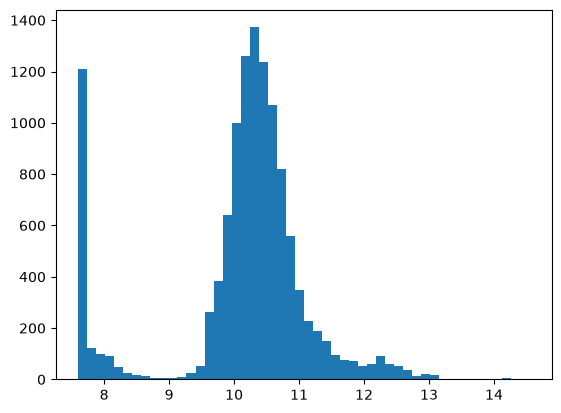

In [4]:
#plt.hist(car_df["msrp"], bins=50)
#plt.hist(car_df[car_df["msrp"] < 100000]["msrp"], bins=50)
msrp_log = np.log1p(car_df["msrp"])
plt.hist(msrp_log, bins = 50)


In [5]:
total_rows = car_df.shape[0]
val_size = int(total_rows * 0.2)
test_size = int(total_rows * 0.2)
train_size = total_rows - val_size - test_size

print(val_size)
print(test_size)
print(train_size)


2382
2382
7150


In [6]:
np.random.seed(2)
idx = np.arange(total_rows)
np.random.shuffle(idx)

val_data = car_df.iloc[idx[:val_size]].reset_index(drop=True)
test_data = car_df.iloc[idx[val_size: val_size + test_size]].reset_index(drop=True)
train_data = car_df.iloc[idx[val_size + test_size: ]].reset_index(drop=True)

len(val_data), len(test_data), len(train_data)

(2382, 2382, 7150)

In [7]:
y_val = np.log1p(val_data["msrp"].values)
y_test = np.log1p(test_data["msrp"].values)
y_train = np.log1p(train_data["msrp"].values)

del val_data["msrp"]
del test_data["msrp"]
del train_data["msrp"]

In [8]:
train_data.iloc[10]



make                        chevrolet
model                 trailblazer_ext
year                             2004
engine_fuel_type     regular_unleaded
engine_hp                       275.0
engine_cylinders                  6.0
transmission_type           automatic
driven_wheels        rear_wheel_drive
number_of_doors                   4.0
market_category                   NaN
vehicle_size                    large
vehicle_style                 4dr_suv
highway_mpg                        18
city_mpg                           13
popularity                       1385
Name: 10, dtype: object

In [9]:
xi = [275, 13, 1385]
x_new = [1] + xi

In [10]:
w0 = 0
w = [0.01, 0.04, 0.002]
w_new = [w0] + w

In [11]:
x1 = [1, 148, 24, 1385]
x2 = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

X = [x1,x2,x10]
X = np.array(X)

X.dot(w_new)

array([5.21 , 6.382, 5.142])

In [12]:
def linear_regression(X):
    return X.dot(w_new)
    

In [13]:
linear_regression(X)

array([5.21 , 6.382, 5.142])

In [38]:
def train_linear_regression(X, y, p=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = np.transpose(X).dot(X)

    w = np.linalg.inv(XTX + p * np.eye(XTX.shape[0])).dot(np.transpose(X)).dot(np.array(y))
    return w[0], w[1:]

In [15]:


X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [748, 14, 185],
    [232, 65, 2031],
    [353, 17, 76],

]
X = np.array(X)
y = [100, 200, 134, 5, 45, 143]




(7150, 5)
(7150,)


<Axes: ylabel='Count'>

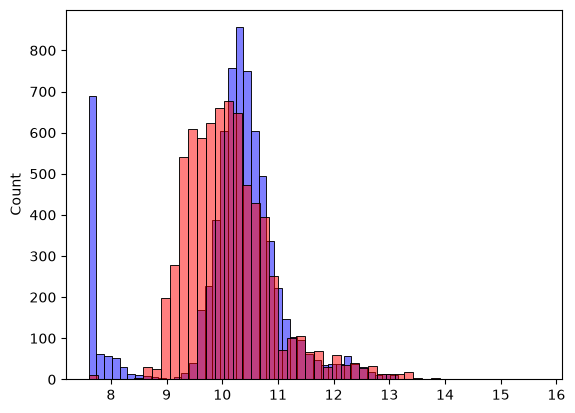

In [16]:

base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']


X = train_data[base].fillna(0).values
y = y_train


print(X.shape)
print(y.shape)

w0, w = train_linear_regression(X, y)
y_train_pred = w0 + X.dot(w)

sns.histplot(y_train, color='blue', alpha=0.5, bins=50)
sns.histplot(y_train_pred, color='red', alpha=0.5, bins=50)


In [17]:
def rmse(pred, actual):
    residuals = (actual - pred) ** 2
    return np.sqrt(residuals.sum()/len(residuals))


In [ ]:

categorical_variables = []
for variable in list(train_data.dtypes.index):
    if train_data.dtypes.loc[variable] == "str":
        categorical_variables.append(variable)

categories = {

}
for var in categorical_variables:
    categories[var] = list(train_data[var].value_counts().head().index)




{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'], 'model': ['silverado_1500', 'tundra', 'f-150', 'beetle_convertible', 'beetle'], 'engine_fuel_type': ['regular_unleaded', 'premium_unleaded_(required)', 'premium_unleaded_(recommended)', 'flex-fuel_(unleaded/e85)', 'diesel'], 'transmission_type': ['automatic', 'manual', 'automated_manual', 'direct_drive', 'unknown'], 'driven_wheels': ['front_wheel_drive', 'rear_wheel_drive', 'all_wheel_drive', 'four_wheel_drive'], 'market_category': ['crossover', 'flex_fuel', 'luxury', 'luxury,performance', 'hatchback'], 'vehicle_size': ['compact', 'midsize', 'large'], 'vehicle_style': ['sedan', '4dr_suv', 'coupe', 'convertible', '4dr_hatchback']}


In [34]:
def prepare_X(df):
    df = df.copy()
    df["age"] = df["year"].max() - df["year"]
    #add number of doors feature
    number_of_doors_features = []
    for v in [2,3,4]:
        df[f"number_of_doors_{v}"] = (df["number_of_doors"] == v).astype(int)
        number_of_doors_features.append(f"number_of_doors_{v}")

    #add categorical features
    categorical_features = []
    for variable in categorical_variables:
        for value in categories[variable]:
            df[f"{variable}_{value}"] = (df[variable] == value).astype(int)
            categorical_features.append(f'{variable}_{value}')



    features = base + ["age"] + number_of_doors_features + categorical_features
    print(df.columns)
    df = df[features]
    X = df.fillna(0).values
    return X


In [39]:
X = prepare_X(train_data)
w0, w = train_linear_regression(X, y_train)

X_val = prepare_X(val_data)
y_val_pred = w0 + X_val.dot(w)

print(rmse(y_val_pred, y_val))


Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'make_chevrolet', 'make_ford',
       'make_volkswagen', 'make_toyota', 'make_dodge', 'model_silverado_1500',
       'model_tundra', 'model_f-150', 'model_beetle_convertible',
       'model_beetle', 'engine_fuel_type_regular_unleaded',
       'engine_fuel_type_premium_unleaded_(required)',
       'engine_fuel_type_premium_unleaded_(recommended)',
       'engine_fuel_type_flex-fuel_(unleaded/e85)', 'engine_fuel_type_diesel',
       'transmission_type_automatic', 'transmission_type_manual',
       'transmission_type_automated_manual', 'transmission_type_direct_drive',
       'transmission_type_unknown', 'driven_wheels_front_wheel_drive',
       'driven_wheels_rear_wheel_drive', 'driven_wheels_all_wheel_drive',
       'driven_wheels_four

In [49]:
df_train_full = pd.concat([train_data, val_data])
df_train_full.reset_index(drop=True, inplace=True)
y_train_full = np.hstack((y_train, y_val))


X_full = prepare_X(df_train_full)

w0, w = train_linear_regression(X_full, y_train_full)

X_test = prepare_X(test_data)
test_pred = w0 + X_test.dot(w)
print(rmse(test_pred, y_test))

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'make_chevrolet', 'make_ford',
       'make_volkswagen', 'make_toyota', 'make_dodge', 'model_silverado_1500',
       'model_tundra', 'model_f-150', 'model_beetle_convertible',
       'model_beetle', 'engine_fuel_type_regular_unleaded',
       'engine_fuel_type_premium_unleaded_(required)',
       'engine_fuel_type_premium_unleaded_(recommended)',
       'engine_fuel_type_flex-fuel_(unleaded/e85)', 'engine_fuel_type_diesel',
       'transmission_type_automatic', 'transmission_type_manual',
       'transmission_type_automated_manual', 'transmission_type_direct_drive',
       'transmission_type_unknown', 'driven_wheels_front_wheel_drive',
       'driven_wheels_rear_wheel_drive', 'driven_wheels_all_wheel_drive',
       'driven_wheels_four